In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns

## Présentation du dataset
Le dataset Wholesale Customers provient de l'UCI Machine Learning Repository. Il contient des informations sur les dépenses annuelles de 440 clients d'un grossiste situé au Portugal.

Chaque ligne représente un client et les dépenses qu'il effectue dans différentes catégories de produits.

L'objectif de notre étude est d'analyser les habitudes de dépenses des clients afin de constituer des groupes de clients ayant des comportements d'achat similaires.

## Description des variables utilisées
Le dataset contient huit variables que nous pouvons répartir en deux catégories.

**Fresh:**	Dépenses annuelles en produits frais

**Milk:** Dépenses annuelles en produits laitiers

**Grocery:** Dépenses annuelles en épicerie

**Frozen:**	Dépenses annuelles en produits surgelés

**Detergents_Paper:** Dépenses annuelles en détergents et papier

**Delicassen:**	Dépenses annuelles en produits de traiteur

**Channel:** Canal de distribution du client

**Region:**	Région géographique du client

## Importation et lecture du jeux données

In [2]:
# URL du dataset
url = "https://archive.ics.uci.edu/static/public/292/data.csv"

# Chargement des données
cah_data = pd.read_csv(url)

# Afficher les premières lignes
cah_data.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [3]:
cah_data.shape

(440, 8)

In [4]:
cah_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [5]:
cah_data.duplicated().sum()

np.int64(0)

In [6]:
# Vérification des dépenses
depenses = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
print("\nValeurs négatives par variable de dépense :")
(cah_data[depenses] < 0).sum()


Valeurs négatives par variable de dépense :


Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

In [7]:
print("\nValeurs égales à zéro par variable de dépense :")
print((cah_data[depenses] == 0).sum())


Valeurs égales à zéro par variable de dépense :
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64


In [8]:
# décription des données
cah_data.describe().T

,count,mean,std,min,25%,50%,75%,max
Channel,440.0,1.322727,0.468052,1.0,1.00,1.0,2.00,2.0
Region,440.0,2.543182,0.774272,1.0,2.00,3.0,3.00,3.0
Fresh,440.0,12000.297727,12647.328865,3.0,3127.75,8504.0,16933.75,112151.0
Milk,440.0,5796.265909,7380.377175,55.0,1533.00,3627.0,7190.25,73498.0
Grocery,440.0,7951.277273,9503.162829,3.0,2153.00,4755.5,10655.75,92780.0
Frozen,440.0,3071.931818,4854.673333,25.0,742.25,1526.0,3554.25,60869.0
Detergents_Paper,440.0,2881.493182,4767.854448,3.0,256.75,816.5,3922.00,40827.0
Delicassen,440.0,1524.870455,2820.105937,3.0,408.25,965.5,1820.25,47943.0


## Conclusion :

L'analyse descriptive porte sur 440 clients et les 8 variables du dataset.

On constate que les dépenses moyennes les plus importantes concernent les produits frais (Fresh), avec environ 12 000 unités, suivis de l'épicerie (Grocery), avec environ 7 951 unités, et des produits laitiers (Milk), avec environ 5 796 unités.

On remarque également que les valeurs maximales sont très éloignées des médianes pour plusieurs variables, notamment Fresh, Milk, Grocery et Delicassen. Cela peut indiquer la présence de valeurs extrêmes.

Les variables Channel et Region sont codées numériquement, mais elles représentent des catégories et non des quantités.

In [9]:
# suppression des 2 variables categoriels
X = cah_data.drop(columns=["Channel", "Region"])

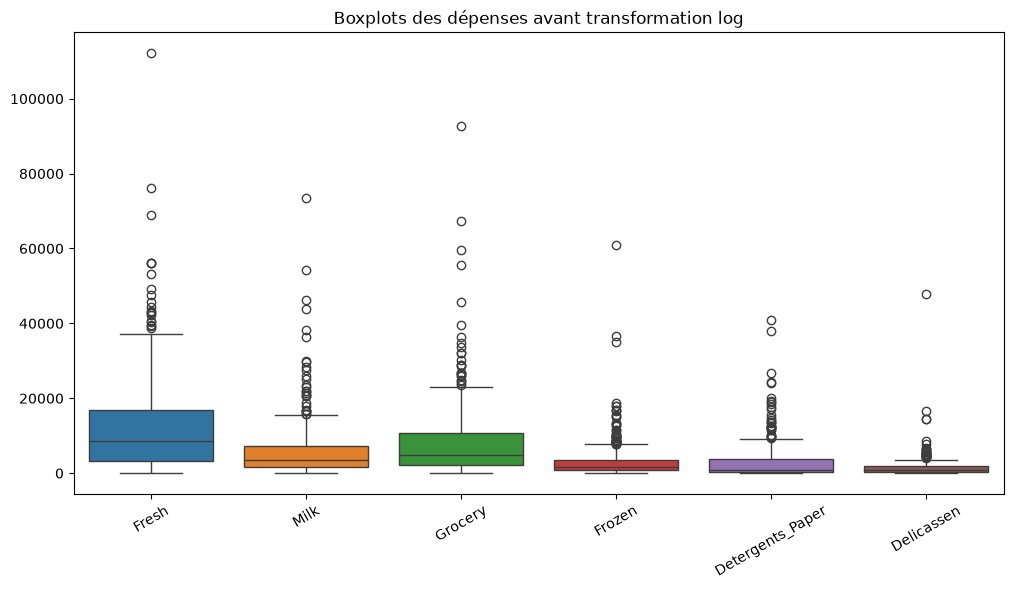

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.boxplot(data=X)
plt.title("Boxplots des dépenses avant transformation log")
plt.xticks(rotation=30)
plt.show()

**Interpretation**

Sur les boxplots des dépenses, on voit beaucoup de points isolés au-dessus des boîtes, surtout pour les produits frais, le lait, l’épicerie et le traiteur. Ça veut dire que certains clients dépensent beaucoup plus que les autres.

Ces valeurs extrêmes ne semblent pas être des erreurs : il n’y a pas de valeurs négatives ni de valeurs manquantes. Ce sont probablement de vrais clients qui achètent beaucoup. Donc je ne les ai pas supprimés

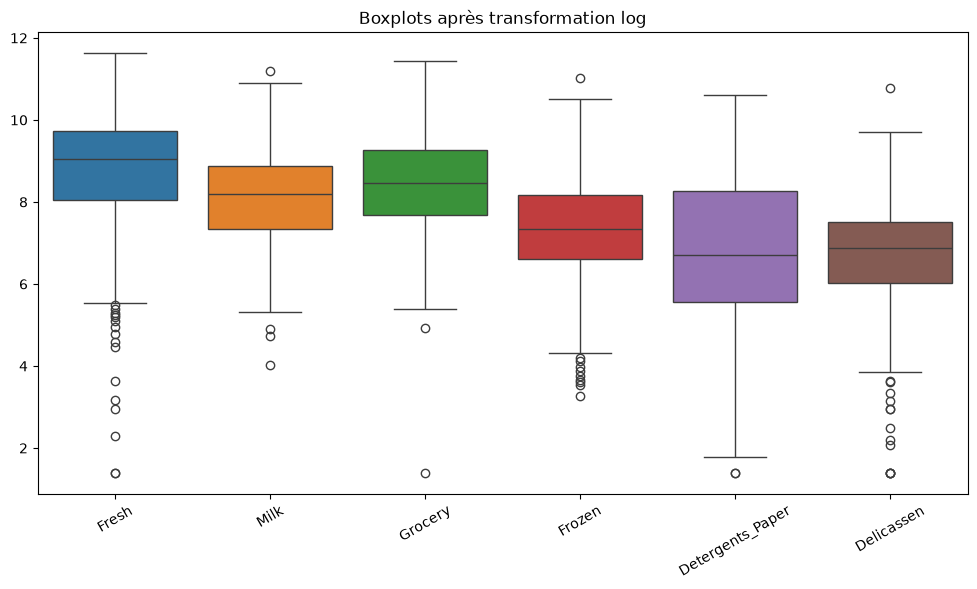

In [11]:
# Appliquer log(1 + x) pour éviter les problèmes avec les zéros
X_log = np.log1p(X)

# Vérifier l'effet avec les boxplots
plt.figure(figsize=(12, 6))
sns.boxplot(data=X_log)
plt.title("Boxplots après transformation log")
plt.xticks(rotation=30)
plt.show()

**Interpretation**

Pour réduire leur influence, j’ai appliqué une transformation logarithmique. Après le log, les boîtes sont plus lisibles et les très grosses valeurs sont beaucoup moins éloignées des autres. Les variables sont aussi plus comparables entre elles.

Mais le log n’a pas tout réglé : quelques clients avec de très petites dépenses, par exemple 4 en produits frais, ressortent maintenant comme des valeurs atypiques en bas

In [70]:
# renomme des index
X_log.index = ['Client' + str(i+1) for i in range(len(X))]
X_log.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Client1,9.446992,9.175438,8.930891,5.370638,7.891705,7.199678
Client2,8.861917,9.191259,9.166284,7.474772,8.099858,7.482682
Client3,8.756840,9.083529,8.947026,7.785721,8.165364,8.967632
Client4,9.492960,7.087574,8.348064,8.764834,6.230481,7.489412
Client5,10.026413,8.596189,8.881697,8.272826,7.483244,8.553718


In [13]:
# Données en format matriciel
y = X_log.values
y[:5]

array([[ 9.44699227,  9.17543832,  8.93089098,  5.37063803,  7.89170466,
         7.19967835],
       [ 8.861917  ,  9.19125948,  9.16628399,  7.47477218,  8.09985791,
         7.48268183],
       [ 8.75683981,  9.08352921,  8.94702566,  7.7857209 ,  8.16536363,
         8.96763167],
       [ 9.49295965,  7.08757371,  8.34806423,  8.76483421,  6.23048145,
         7.48941208],
       [10.0264129 ,  8.5961892 ,  8.88169741,  8.272826  ,  7.48324442,
         8.55371797]])

In [14]:
# Importation normalize
from sklearn.preprocessing import normalize
# Normaliser y
y = normalize(y)
y[:5]

array([[0.47463738, 0.46099392, 0.44870733, 0.2698325 , 0.39649636,
        0.36172745],
       [0.43011716, 0.44610195, 0.44488975, 0.36279146, 0.39313028,
        0.36317536],
       [0.41420699, 0.42965972, 0.42320297, 0.36827213, 0.3862296 ,
        0.42417765],
       [0.48584665, 0.36273977, 0.42725127, 0.44858143, 0.31887406,
        0.38330573],
       [0.47217107, 0.40481794, 0.4182633 , 0.38958989, 0.35240634,
        0.40281785]])

In [15]:
# Importation PCA
from sklearn.decomposition import PCA
pca_model_cah_data= PCA(n_components = 2)
# Matrice des 2 composantes
feature_pca = pca_model_cah_data.fit_transform(y)
# Convertir la matrice features_pca en dataframe
New_cah_data = pd.DataFrame(feature_pca, columns = ['PC1', 'PC2'])

In [16]:
# Part de variance des 2 composantes
np.round(sum(pca_model_cah_data.explained_variance_ratio_)*100, 2)

np.float64(73.02)

## Kmeans

In [17]:
# Importation de kmeans
from sklearn.cluster import KMeans

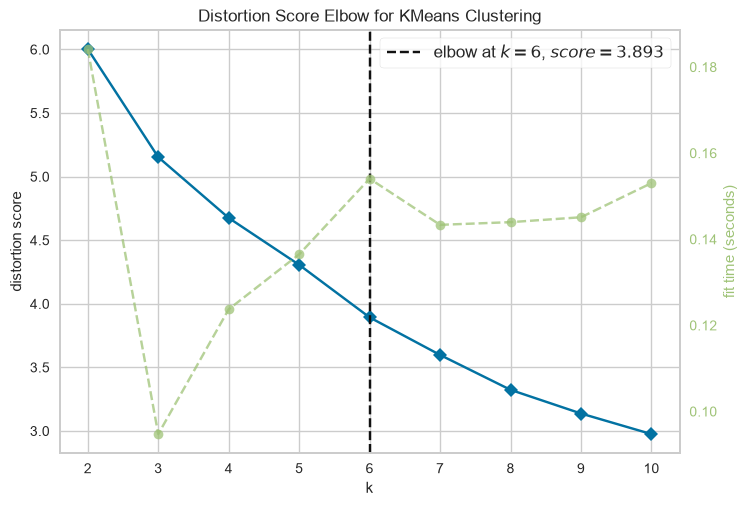

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [18]:
# importation KELbowVisualizer
from yellowbrick.cluster import KElbowVisualizer
kmeans_model = KMeans(init = 'random', max_iter=500)
# Instantie du  KELbowVisualizer
Elbow_M = KElbowVisualizer(kmeans_model, k=10)
# Entrainement d model
Elbow_M.fit(y)
# Visualisation de l'elbow
Elbow_M.show()

**Interpretation**

Sur le graphique, on voit que l'algorithme propose k = 6, avec un score de 3,90. La courbe bleue descend vite entre 2 et 4 clusters, puis elle continue de baisser plus doucement. Comme le coude est autour de 5 ou 6, on peut hésiter. Pour vérifier quel est le meilleur choix, on va comparer les résultats de k = 4, k = 5 et k = 6 avec le score de silhouette.

In [19]:
kmeans_model = KMeans(n_clusters=5, init='k-means++', max_iter=500, random_state=42)
# entraînement du modèle
kmeans_model.fit(y)

KMeans(max_iter=500, n_clusters=5, random_state=42)

In [20]:
kmeans_model_k4 = KMeans(n_clusters=4, init='k-means++', max_iter=500, random_state=42)
kmeans_model_k4.fit(y)

KMeans(max_iter=500, n_clusters=4, random_state=42)

In [21]:
kmeans_k6 = KMeans(n_clusters=6, init='k-means++', max_iter=500, random_state=42)
kmeans_k6.fit(y)

KMeans(max_iter=500, n_clusters=6, random_state=42)

## Prédiction

In [22]:
# Prediction de la partition des données
kmeans_partition_k6 = kmeans_k6.predict(y)
# Affichage de la partition
kmeans_partition_k6[: 100]

array([2, 3, 3, 1, 3, 3, 2, 3, 2, 2, 2, 1, 2, 0, 2, 3, 2, 3, 3, 2, 3, 1,
       1, 3, 3, 0, 1, 1, 2, 3, 3, 3, 3, 1, 3, 4, 3, 2, 2, 1, 1, 3, 0, 4,
       0, 2, 2, 2, 2, 2, 1, 2, 3, 4, 1, 3, 2, 2, 1, 2, 2, 2, 3, 2, 3, 4,
       4, 2, 3, 0, 1, 3, 0, 1, 3, 1, 3, 2, 1, 3, 3, 4, 2, 1, 0, 2, 2, 3,
       1, 1, 1, 1, 2, 1, 2, 5, 4, 1, 1, 1], dtype=int32)

In [23]:
# Prediction de la partition des données
kmeans_partition_k4 = kmeans_model_k4.predict(y)
# Affichage de la partition
kmeans_partition_k4[: 100]

array([3, 3, 3, 1, 3, 3, 3, 3, 3, 2, 3, 1, 3, 0, 3, 3, 2, 3, 3, 3, 3, 1,
       1, 3, 3, 0, 1, 1, 2, 1, 3, 3, 3, 1, 3, 2, 3, 0, 2, 1, 1, 3, 0, 0,
       0, 2, 2, 3, 3, 2, 1, 0, 3, 2, 1, 3, 2, 2, 1, 3, 0, 0, 3, 3, 3, 2,
       2, 3, 3, 3, 1, 3, 0, 1, 3, 1, 3, 0, 1, 3, 3, 2, 3, 1, 0, 2, 0, 1,
       1, 1, 1, 1, 2, 1, 0, 2, 2, 1, 1, 1], dtype=int32)

In [24]:
# Prediction de la partition des données
kmeans_partition = kmeans_model.predict(y)
# Affichage de la partition
kmeans_partition[: 100]

array([2, 3, 3, 1, 3, 3, 2, 3, 2, 2, 2, 1, 2, 2, 2, 3, 2, 3, 3, 2, 3, 1,
       1, 3, 3, 0, 1, 1, 2, 3, 3, 3, 3, 1, 3, 2, 3, 2, 2, 1, 1, 3, 0, 0,
       0, 2, 2, 2, 2, 2, 1, 2, 3, 4, 1, 3, 2, 2, 1, 2, 2, 2, 3, 2, 3, 4,
       4, 2, 3, 3, 1, 3, 0, 1, 3, 1, 3, 2, 1, 3, 3, 4, 2, 1, 0, 2, 2, 3,
       1, 1, 1, 1, 2, 1, 2, 4, 4, 1, 1, 1], dtype=int32)

In [25]:
# Nombre d'observations dans chaque classe pour k4
val = pd.Series(kmeans_partition_k4).value_counts()
val

1    185
3    139
2     71
0     45
Name: count, dtype: int64

In [26]:
# Nombre d'observations dans chaque classe por k6
val = pd.Series(kmeans_partition_k6).value_counts()
val

1    174
3    113
2     95
0     30
4     25
5      3
Name: count, dtype: int64

In [27]:
# Nombre d'observations dans chaque classe pour k5
val = pd.Series(kmeans_partition).value_counts()
val

1    175
3    115
2    102
0     27
4     21
Name: count, dtype: int64

In [28]:
# Function de visualisation du diagramme en barre des nombres d'observations.
def bar_plot(val):
  fig = px.bar(x = val.index.astype(str), y = val.values, color = val.index.astype(str), text_auto = True)
  fig.show()

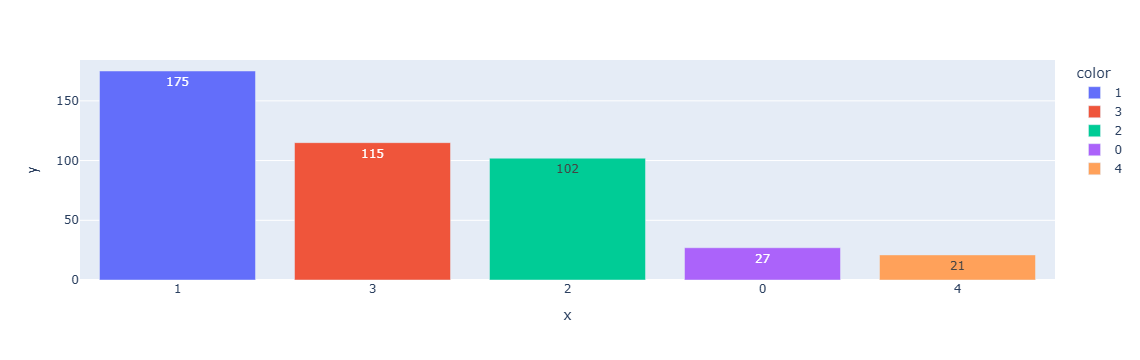

In [29]:
# visualiser le diagramme des nombres d'observations
bar_plot(val)

In [30]:
# Function de visualisuation des classes pour k5
def scatter_plot(New_cah_data,Pred):
  fig = px.scatter(New_cah_data, x='PC1', y='PC2', color=Pred.astype(str))
  fig.show()

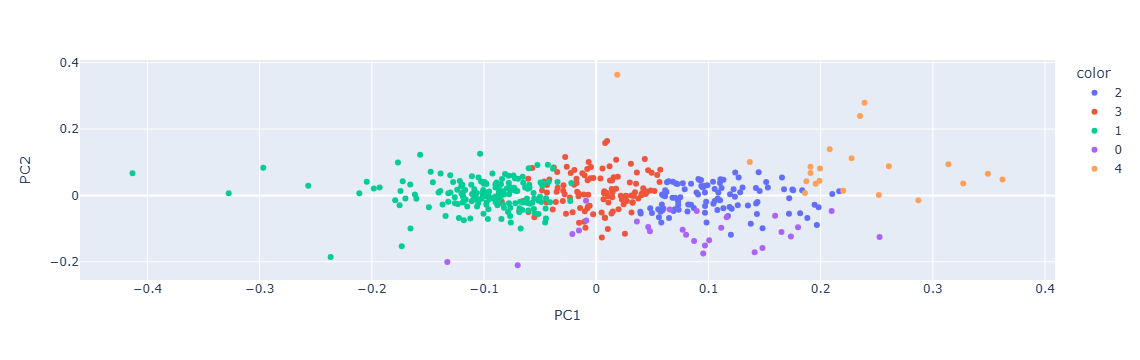

In [31]:
# Visualiser les classes
scatter_plot(New_cah_data,kmeans_partition)

**Interpretation**

Sur ce graphique, on voit les 5 groupes en deux dimensions. Le cluster 1 (vert) se trouve à gauche, le cluster 3 (rouge) au centre et le cluster 2 (bleu) juste à sa droite. Plus à droite, on retrouve le cluster 0 (violet) en bas et le cluster 4 (orange) en haut. Par contre, les clusters 2 et 0 se mélangent un peu à droite, et les clusters 1 et 3 se touchent au milieu. On remarque donc que les 5 groupes ne sont pas complètement séparés les uns des autres.

In [32]:
# Function de visualisuation des classes pour k6
def scatter_plot(New_cah_data,Pred):
  fig = px.scatter(New_cah_data, x='PC1', y='PC2', color=Pred.astype(str))
  fig.show()

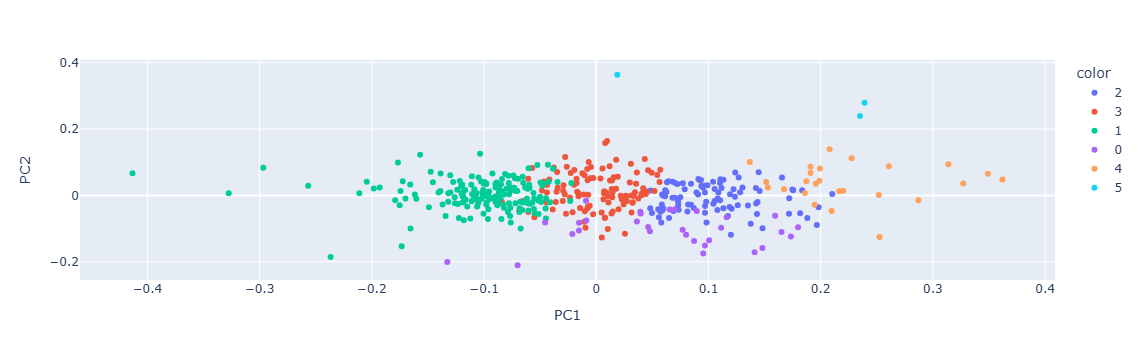

In [33]:
# Visualiser les classes pour k6
scatter_plot(New_cah_data,kmeans_partition_k6)

**Interpretation**

Sur ce graphique, on voit les 6 groupes. Le cluster 1 (vert) est à gauche, le cluster 3 (rouge) au centre et le cluster 2 (bleu foncé) juste à sa droite. Plus à droite, on retrouve le cluster 0 (violet) en bas et le cluster 4 (orange) au milieu, qui se mélangent beaucoup entre eux. Enfin, le cluster 5 (bleu clair) ne contient que trois points isolés tout en haut. Donc, ajouter un sixième groupe n'améliore pas vraiment la séparation. Il vaut mieux choisir un nombre de clusters plus petit

In [34]:
# Function de visualisuation des classes pour k4
def scatter_plotk4(New_cah_data,Pred):
  fig = px.scatter(New_cah_data, x='PC1', y='PC2', color=Pred.astype(str))
  fig.show()

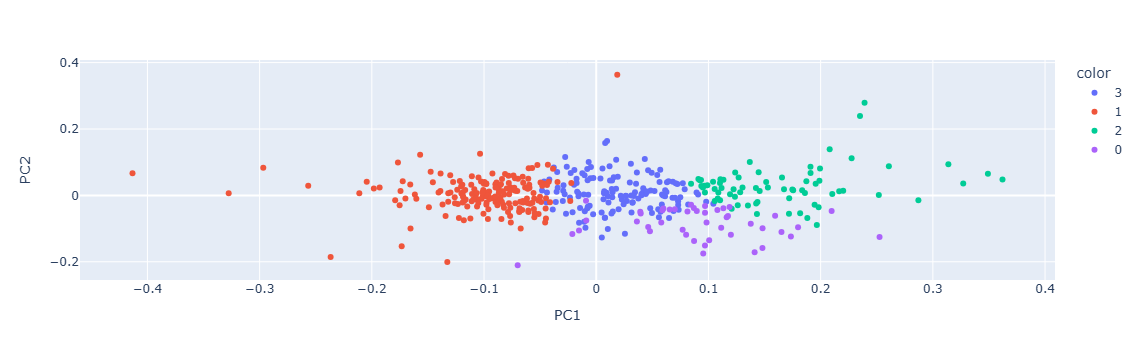

In [35]:
# Visualiser les classes pour k4 
scatter_plotk4(New_cah_data,kmeans_partition_k4)

**Interpretation**

Sur ce graphique, on voit les 4 groupes, et le résultat est plus clair qu'avec 5 ou 6 clusters. Chaque groupe est mieux réparti : le cluster 1 (rouge) se trouve à gauche, le cluster 3 (bleu) au centre, le cluster 2 (vert) à droite plutôt en haut et le cluster 0 (violet) en bas à droite. Cette fois, les groupes se mélangent beaucoup moins. Visuellement, le choix de 4 clusters semble donc plus intéressant.

## Indice de silhouette de la partition du Kmeans

In [36]:
# Silhouette score pour k4
from sklearn.metrics import silhouette_score
sil_kmeans_k4 = silhouette_score(y,kmeans_partition_k4)
print(f"La silhouette score : {sil_kmeans_k4} ")

La silhouette score : 0.2284238709037783 


In [37]:
# Silhouette score pour k6
from sklearn.metrics import silhouette_score
sil_kmeans_k6 = silhouette_score(y,kmeans_partition_k6)
print(f"La silhouette score : {sil_kmeans_k6} ")

La silhouette score : 0.2098730299866904 


In [38]:
# Silhouette score pour k5
from sklearn.metrics import silhouette_score
sil_kmeans = silhouette_score(y,kmeans_partition)
print(f"La silhouette score : {sil_kmeans} ")

La silhouette score : 0.21181902619770437 


**Conclusion**

Pour choisir le meilleur nombre de clusters, nous avons utilisé trois critères. D'abord, la méthode du coude nous a indiqué une valeur de 6 , mais la courbe était très progressive. Nous avons donc testé 4, 5 et 6 clusters.
Ensuite, avec le score de silhouette, nous avons obtenu le meilleur résultat pour k = 4, avec un score de 0,22. C'est mieux que k = 5 (0,21) et k = 6 (0,20).
Enfin, en regardant les graphiques de l'ACP, on voit que les 4 groupes sont mieux séparés et plus équilibrés. Avec 5 ou 6 groupes, certains clusters se mélangent davantage ou isolent trop peu de clients.
Nous avons donc choisi k = 4, car c'est le découpage qui donne le meilleur résultat parmi les trois possibilités testées.

## CAH

In [39]:
# Importation de linkage et dendrogram
from scipy.cluster.hierarchy import  linkage, dendrogram

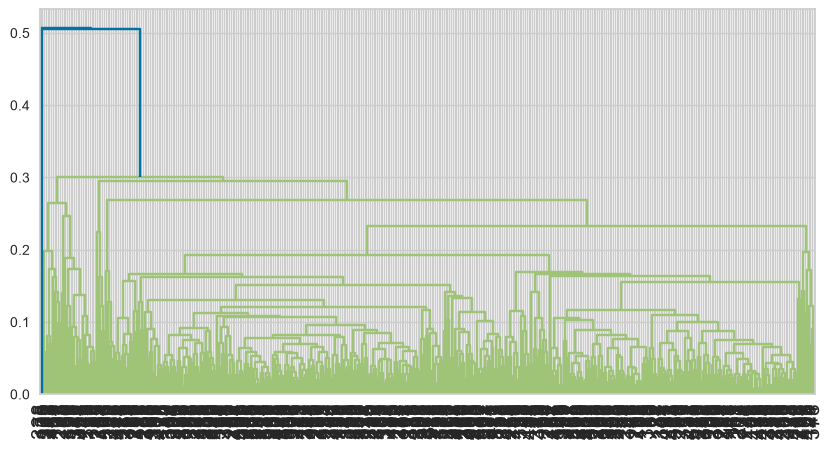

In [40]:
# Visualisation du dendrograme
import matplotlib.pyplot as plt
Z = linkage(y, 'average')# matrice des liaisons
plt.figure(figsize=(10, 5))
dendro = dendrogram(Z, leaf_font_size=15, orientation = 'top')

**Interpretation**

Sur ce dendrogramme, on voit comment les données se regroupent. On remarque d'abord un point complètement isolé tout à gauche, relié tout en haut en bleu vers 0,50. Tout le reste des données forme un seul grand bloc vert en dessous de 0,30, avec quelques petites branches qui se détachent sur la gauche.
Si on coupe l'arbre tout en haut autour de 0,40, on obtient 2 groupes. Si on coupe juste au niveau des premières branches vertes autour de 0,30, on obtient 3 groupes, et un peu plus bas vers 0,295, on obtient 4 groupes. Cela nous permet de voir comment choisir le nombre de clusters.

In [41]:
from sklearn.cluster import AgglomerativeClustering
cah_model = AgglomerativeClustering(n_clusters =2, linkage = 'average')
# Entrainement du  modèle pour k4
cah_model.fit(y)

AgglomerativeClustering(linkage='average')

In [42]:
from sklearn.cluster import AgglomerativeClustering

cah_model_k3 = AgglomerativeClustering(n_clusters =3, linkage = 'average')
# Entrainement du modèle
cah_model_k3.fit(y)

AgglomerativeClustering(linkage='average', n_clusters=3)

In [43]:
# Prédiction de la partition des données pour k4
cah_partition = cah_model.fit_predict(y)
# Affichage la partition
cah_partition[:100]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [44]:
# Prédiction de la partition des données pour k3
cah_partition_k3 = cah_model_k3.fit_predict(y)
# Affichage de la partition
cah_partition_k3[:100]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [45]:
# Nombre d'observations dans chaque classe pour k4
val1  = pd.Series(cah_partition).value_counts()
val1

0    439
1      1
Name: count, dtype: int64

In [46]:
# Nombre d'observations dans chaque classe pour k3
val3  = pd.Series(cah_partition_k3).value_counts()
val3

0    438
2      1
1      1
Name: count, dtype: int64

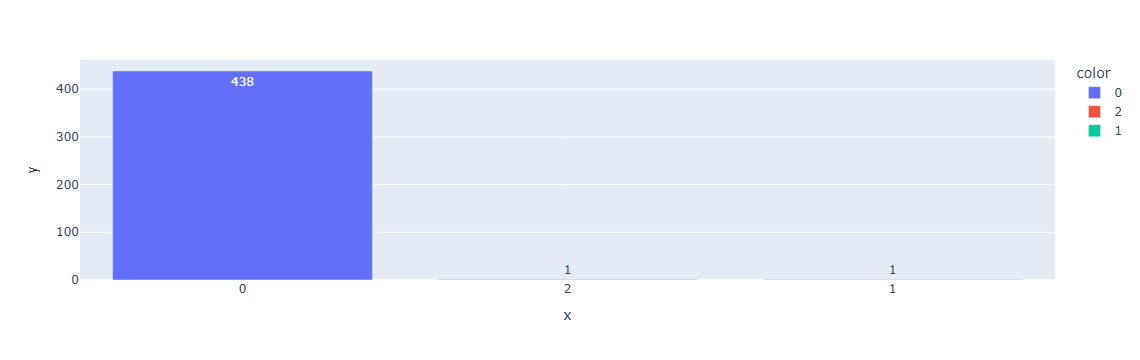

In [47]:
# Diagramme en barre des nombres d'observations
bar_plot(val3)

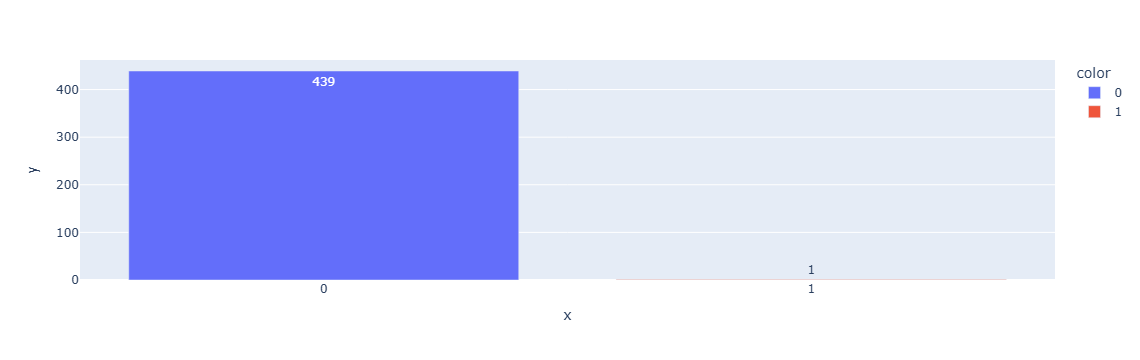

In [48]:
# Diagramme en barre des nombres d'observations
bar_plot(val1)

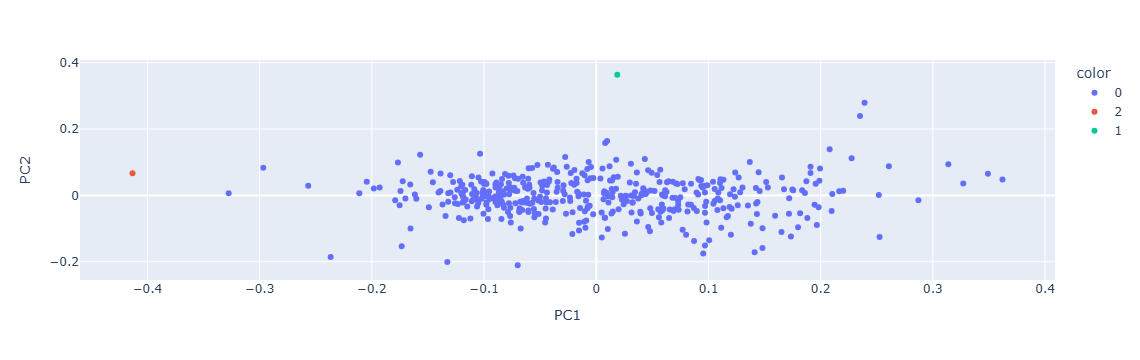

In [49]:
# Visualiser les classes pour k3
scatter_plot(New_cah_data, cah_partition_k3)

**Interpretation**

Sur ce graphique, on voit les 3 groupes obtenus avec la CAH. Le cluster 0 (bleu) regroupe la quasi-qu'un seul point isolé tout en haut. On remarque donc que les groupes sont très déséquilibrés, car la CAH a simplement isolé deux clients atypiques du reste des données.

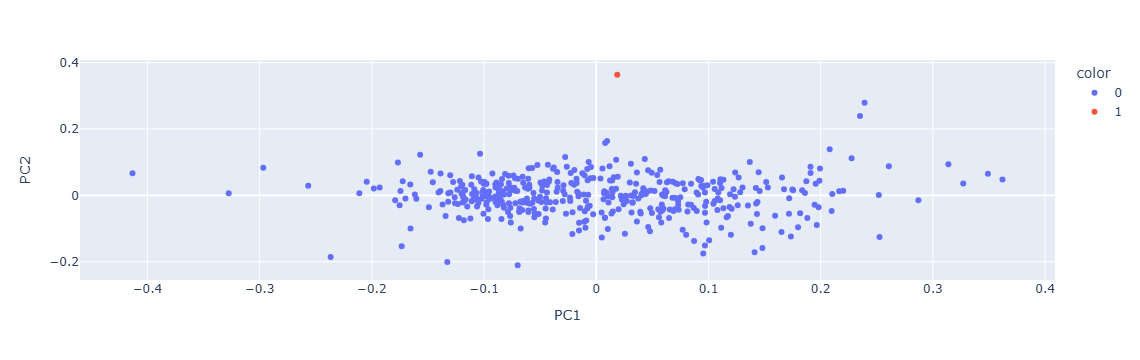

In [50]:
# Visualiser les classes pour k4
scatter_plot(New_cah_data, cah_partition)

**Interpretation**

Sur ce graphique, on voit les 2 groupes obtenus avec la CAH. Le cluster 0 (bleu) regroupe presque tous les clients, tandis que le cluster 1 (rouge) ne contient qu'un seul point isolé tout en haut. Cela correspond bien à ce qu'on avait remarqué tout en haut du dendrogramme, avec une première branche qui se détachait toute seule.
On remarque donc que, contrairement au K-means avec 4 clusters, la CAH donne ici des groupes très déséquilibrés.

In [51]:
# Silhouette score pour k3
sil_cah_k3 = silhouette_score(y, cah_partition_k3)
print(f"La silhouette score :{sil_cah_k3}")

La silhouette score :0.5983935571257744


In [52]:
# Silhouette score pour k2
sil_cah = silhouette_score(y, cah_partition)
print(f"La silhouette score :{sil_cah}")

La silhouette score :0.6320768437897699


**Conclusion**

En comparant les deux modèles de CAH, on constate que le découpage en 2 clusters est plus intéressant que celui en 3. D'abord, le dendrogramme montre bien qu'on peut couper au niveau des premières branches autour de 0,30 pour obtenir 3 groupes. Ensuite,  le score de silhouette est l plus élevé avec k = 2 (0,63) qu'avec k = 3, le découpage en 2 ne fait qu'isoler un seul client. Enfin, en regardant les graphiques de l'ACP, on remarque qu'avec 3 clusters, on obtient un grand groupe principal et deux points isolés.
Nous avons donc choisi k = 2 pour notre modèle de CAH.

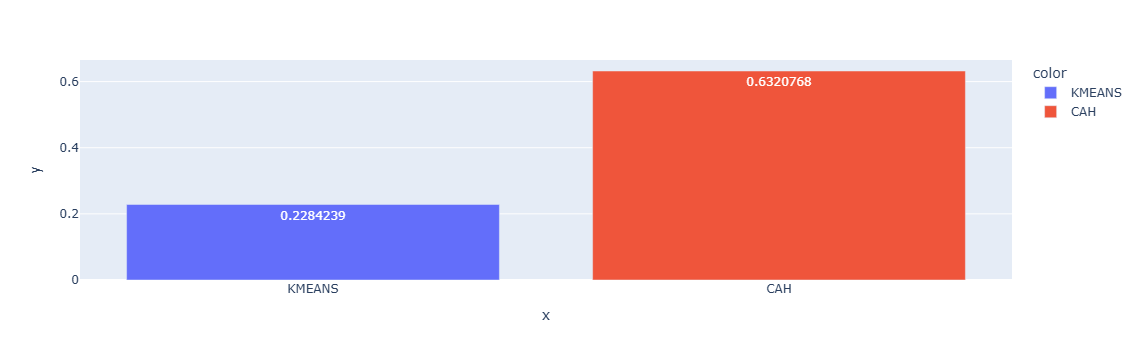

In [53]:
# Diagrammes en barre des silhouettes
Model_Names = ['KMEANS', 'CAH']
sil = [sil_kmeans_k4, sil_cah]
fig = px.bar(x= Model_Names, y = sil, color = Model_Names, text_auto = True)
fig.show()

## Choix du Kmeans

Pour finir, j’ai comparé K-Means et la CAH, et j’ai retenu K-Means avec 4 groupes.

D’abord, la CAH a un meilleur score de silhouette, 0,63 contre 0,22. Quand on regarde les groupes, la CAH met 438 clients dans un seul groupe, et elle isole seulement 2 clients dans deux autres. Ce n’est pas un vrai découpage, donc ça ne nous apprend rien sur les clients.

K-Means, au contraire, donne 4 groupes équilibrés, de 185, 139, 71 et 45 clients. Et pour le nombre de groupes, k = 4 a le meilleur score parmi , 5 et 6.

Enfin, les 4 groupes sont faciles à interpréter : on peut dire ce que chacun achète le plus.

Donc même si son score est plus bas, K-Means est le modèle le plus utile ici.

In [71]:
# les clients
cluster_names = []
for i in range(4):
  cluster_names.append(list(X_log.index[kmeans_partition_k4 == i]))

In [72]:
# Les clients de la classe 0
print(cluster_names[0])

['Client14', 'Client26', 'Client38', 'Client43', 'Client44', 'Client45', 'Client52', 'Client61', 'Client62', 'Client73', 'Client78', 'Client85', 'Client87', 'Client95', 'Client110', 'Client124', 'Client129', 'Client138', 'Client164', 'Client165', 'Client185', 'Client188', 'Client189', 'Client204', 'Client208', 'Client222', 'Client229', 'Client234', 'Client269', 'Client286', 'Client287', 'Client296', 'Client302', 'Client304', 'Client313', 'Client319', 'Client332', 'Client344', 'Client350', 'Client376', 'Client380', 'Client408', 'Client409', 'Client425', 'Client440']


## Déploiement du meilleur modèle (CAH) avec Gradio

In [56]:
def predire_classe(nouveau_client):
    client = np.log1p(np.array(nouveau_client, dtype=float)).reshape(1, -1)
    client = normalize(client)
    distances = cdist(client, centroides)
    return classes[distances.argmin()]

In [57]:
import numpy as np
import tqdm as notebook_tqdm
import gradio as gr
from scipy.spatial.distance import cdist

# Calcule des centroïdes
classes = np.unique(kmeans_partition_k4)
centroides = np.array([y[kmeans_partition_k4 == c].mean(axis=0) for c in classes])

# Prédiction : la classe du centroïde le plus proche
def predire_classe(nouveau_client):
    client = normalize(np.array(nouveau_client, dtype=float).reshape(1, -1))
    distances = cdist(client, centroides)
    return classes[distances.argmin()]

C:\Users\Fatou Ndiaye\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [58]:
print("Classe prédite  :", predire_classe(X.iloc[2].values))
print("Classe réelle de K-Means :", kmeans_partition_k4[2])

Classe prédite  : 3
Classe réelle de K-Means : 3


In [59]:
pred = np.array([predire_classe(ligne) for ligne in X_log.values])
print("Accord :", round((pred == kmeans_partition_k4).mean() * 100, 1), "%")

Accord : 100.0 %


In [60]:
profil_moyen = X.groupby(kmeans_partition_k4).mean().round(0)
display(profil_moyen)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,8449.0,8945.0,12994.0,1471.0,5798.0,289.0
1,17065.0,2714.0,3060.0,5211.0,379.0,1447.0
2,2899.0,10851.0,18383.0,938.0,8552.0,1642.0
3,11058.0,6297.0,7501.0,1833.0,2371.0,1969.0


In [61]:
# Noms des classes
noms_classes = {
    0: "Épicerie, lait et détergents, très peu de traiteur et de surgelés",
    1: "Produits frais et surgelés, très peu d'épicerie et de détergents",
    2: "Plus gros acheteurs d'épicerie, détergents et lait, très peu de produits frais",
    3: "Profil moyen : achats équilibrés, un peu de traiteur"
}

## Interpretation

Pour interpréter les groupes, j’ai calculé les dépenses moyennes de chaque groupe, puis je les ai comparées à la moyenne de tous les clients. Comme ça, je vois ce que chaque groupe achète.

Groupe 1 : 185 clients

C’est le plus grand groupe. Ces clients achètent beaucoup de produits frais, environ 17 000 en moyenne. Ils achètent aussi beaucoup de surgelés. Par contre, ils achètent très peu de détergents, et aussi peu d’épicerie et de lait.

Groupe 3 : 139 clients

C’est un profil moyen. Leurs dépenses sont proches de la moyenne dans presque toutes les catégories. Les deux seules différences : ils achètent un peu plus de traiteur, et un peu moins de surgelés.

Groupe 2 : 71 clients

Ce sont les plus gros acheteurs d’épicerie, avec plus de 18 000 en moyenne. Ils achètent aussi beaucoup de détergents et de papier, et beaucoup de lait. En revanche, ils achètent très peu de produits frais, et de surgelés.

Groupe 0 : 45 clients

C’est le plus petit groupe. Il ressemble un peu au groupe 2, parce qu’il achète aussi plus d’épicerie, de lait et de détergents. Mais la grande différence, c’est qu’il achète presque pas de traiteur.

## La fonction appelée par l'application

In [62]:
def affecter_client(channel, region, *depenses):
    classe = predire_classe(depenses)

    return (
        f"Channel : {channel}\n"
        f"Region : {region}\n"
        f"Classe attribuée : {classe}"
    )

## L'interface Gradio

In [63]:
import gradio as gr

champs = [
    gr.Dropdown(
        choices=[("Horeca", 1), ("Retail", 2)],
        label="Channel",
        value=1
    ),
    gr.Dropdown(
        choices=[("Lisbonne", 1), ("Porto", 2), ("Autre", 3)],
        label="Region",
        value=3
    )
] + [
    gr.Number(
        label=col,
        value=float(X[col].median())
    )
    for col in X.columns
]

In [66]:
def affecter_client(*valeurs):
    if any(v is None or v < 0 for v in valeurs):
        raise gr.Error("Aucun champ ne peut être vide ou négatif.")
    client = normalize(np.array(valeurs, dtype=float).reshape(1, -1))
    g = int(classes[cdist(client, centroides).argmin()])
    return f"Groupe {g} : {noms_classes[g]}"

In [67]:
import gradio as gr

# Un champ par variable, prérempli avec la valeur médiane
champs = [gr.Number(label=col, value=float(X_log[col].median()))
          for col in X_log.columns]
exemples = X_log.head(3).values.tolist()
interface = gr.Interface(
    fn=affecter_client,
    inputs=champs,
    outputs=gr.Textbox(label="Résultat"),
    title="Segmentation des verres - modèle CAH",
    description="Saisissez la composition d'un verre pour connaître son groupe.",
    examples=exemples,
)

In [68]:
interface = gr.Interface(
    fn=affecter_client,
    inputs=champs,
    outputs=gr.Textbox(label="Résultat"),
    title="Segmentation des clients - modèle CAH",
    description="Saisissez les caractéristiques d'un client pour connaître sa classe.",
    examples=exemples
)

interface.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


In [69]:
import joblib
joblib.dump({
    "methode": "CAH",
    "kmeans_model_k4": kmeans_model_k4,
    "centroides": centroides,
    "classes": np.array([0, 1, 2]),
    "colonnes": list(X.columns),
    "descriptions": noms_classes,
    "normalisation": "normalize",
    "medianes": X.median().to_dict()
}, "modeles/depense.pkl")

['modeles/depense.pkl']